# Notebook — Phone forced alignment + SAE hub-and-spoke experiments (Colab T4)

- `bcresnet_sae/checkpoints/bcresnet_tau{τ}_final.pt` (at least τ=3; τ=1 and τ=8 if possible)
- the mel cache and `file_list.json` in `bcresnet_sae/cache/` (**this file defines the row order**)

**Pipeline**
1. **Forced alignment** — Frame-level phone labels are produced with a wav2vec2 phoneme CTC model (`facebook/wav2vec2-lv-60-espeak-cv-ft`) and `torchaudio.functional.forced_align`. *MFA is replaced by wav2vec2 CTC alignment, because installing MFA through conda on Colab is very cumbersome.* (The purpose is the same: to align the known phone sequence of each word to the audio.) The result is cached on Drive, and the cell resumes if it is interrupted. A QC visualization cell is included.
2. **Activation dump** — The outputs of all 4 stages are captured in one forward pass. The SAE input is the **flatten(C×F) vector** of each frame. (It is not averaged over frequency, so that the reconstruction can be patched back into the model exactly.)
3. **Hub-and-spoke runner** — One `MAIN` configuration plus spokes along each axis (stage / expansion / L0 / seed / τ), about 15 runs in total. Finished runs are skipped by checking the CSV and the checkpoint, so the runner is **resumable**. By design, the τ=8 spoke runs only Phases 1–2 (no interventions).
4. **Analysis** — phone purity/coverage, comparison with baselines (raw/PCA/random), spoke comparison figure (MAIN = red star), full ablation suite, and minimal-pair steering. All of these use the MAIN cell.

**Expected time (T4)**: alignment ~40–60 min (once) / dump ~10–20 min per τ (once) / ~5–15 min per SAE run / full ablation ~30–60 min / steering ~15 min

**Disk**: Activation dumps are stored locally in `/content` (~35 GB for 3 values of τ). They are deleted when the session ends, but they are quick to regenerate (one forward pass).

> All text in figures (titles, axis labels, legends, captions) is written **in English only**.


---
### 🔧 v2 changes (pipeline bug fixes)

This notebook is a revised version that fixes pipeline bugs found in an earlier run. The causes and the fixes are listed below.

1. **[Main fix] CTC peaky alignment was not corrected (cell 3a)** — The CTC path of `forced_align` marks each phone on only 1–2 wav2vec2 frames (≈2–4 mel frames) and marks the rest as blank. The earlier version labeled only these token spans as phones. Therefore, almost no valid frames were left once the boundary margin (±2–8 frames) was applied. As a result, every run had `purity=0.000, coverage=0.000`; probe phones were "selected" in alphabetical order (`['aɪ','aʊ','b']`) regardless of their scores; every Mann-Whitney test in the baseline comparison returned NaN; and cell 10a found 0 candidate phones, which caused an **`IndexError` at `top3[0]` in cell 10c**. → In v2, the blank gap between adjacent tokens is split at its midpoint, so that each phone covers a contiguous segment. Only the first and the last phone of a word are extended by 40 ms. The label file is renamed to `phone_labels_v2_i16.npy`, so the alignment is run once more.
2. **Boundary margin was too large (cell 4)** — `MARGINS=[2,3,5,8]` is too large compared with typical phone lengths (5–15 mel frames). Even with corrected labels, every phone shorter than 17 frames (170 ms) would be excluded at stage 3. → Relaxed to `[1,1,2,3]`.
3. **Steering pair design error (cell 11)** — In `('four','forward')`, both words begin with /f/. So the pair does not fit the design, which replaces the word-initial phone, and it raised an **AssertionError**. → Replaced by `('nine','five')`.
4. **Cache invalidation** — The metrics depend on the labels, so the file names were changed to `sae_runs_v2.csv` / `probe_phones_v2.json`. SAE training does not depend on the labels. Therefore **existing SAE checkpoints are reused**, and only the metrics are recomputed (this saves a few minutes per run).
5. **Defensive checks added** — a sanity check on phone segment lengths after alignment (3a), an assert on npk when probe phones are selected (6b), a guard against empty arrays in the baseline comparison and compatibility with matplotlib 3.9 `tick_labels` (8), and guards against empty results in 10b/10c.
6. **Bias in the seed-reproducibility metric (cell 9b)** — Dead latents (random initial directions) were included, so the cross-seed cosine was biased downward. Now only latents that actually fire are compared.

Note: A high dead-latent fraction (49–89%) is not a bug. It is a known behavior of TopK SAEs trained without an auxiliary loss. Take it into account when interpreting the results, and add an aux-k loss or dead-latent re-initialization if needed.

In [ ]:
# ============ 0. Environment setup ============
from google.colab import drive
drive.mount('/content/drive')

import subprocess
subprocess.run(['apt-get', '-qq', 'install', '-y', 'espeak-ng'], check=True)
subprocess.run(['pip', '-q', 'install', 'transformers', 'phonemizer'], check=True)

import os, json, math, time, random
from contextlib import contextmanager, nullcontext
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchaudio
import matplotlib.pyplot as plt

DRIVE_ROOT  = '/content/drive/MyDrive/bcresnet_sae'
CKPT_DIR    = os.path.join(DRIVE_ROOT, 'checkpoints')
CACHE_DIR   = os.path.join(DRIVE_ROOT, 'cache')
RESULTS_DIR = os.path.join(DRIVE_ROOT, 'results')
SAE_DIR     = os.path.join(DRIVE_ROOT, 'sae')
for d in (RESULTS_DIR, SAE_DIR):
    os.makedirs(d, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

def seed_all(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

seed_all(0)
print(device, torch.__version__)


Mounted at /content/drive
cuda 2.11.0+cu128


In [ ]:
# ============ 1. Data: download audio + load the Notebook 1 cache ============
# The alignment needs waveforms, so the audio is downloaded again.
# The mel features, labels, and file order must come from the Notebook 1 cache on Drive.
DATA_ROOT = '/content/data'
os.makedirs(DATA_ROOT, exist_ok=True)
_ = torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True)
SC_DIR = os.path.join(DATA_ROOT, 'SpeechCommands', 'speech_commands_v0.02')

FL_JSON = os.path.join(CACHE_DIR, 'file_list.json')
MEL_X   = os.path.join(CACHE_DIR, 'mel_x_f16.npy')
META    = os.path.join(CACHE_DIR, 'mel_meta.npz')
assert os.path.exists(FL_JSON) and os.path.exists(MEL_X) and os.path.exists(META), \
    'The Notebook 1 cache is missing. Run Notebook 1 first.'

fl = json.load(open(FL_JSON))
WORDS, file_list, CFG = fl['words'], fl['files'], fl['cfg']
W2I = {w: i for i, w in enumerate(WORDS)}
meta = np.load(META)
y, split = meta['y'], meta['split']
X = np.load(MEL_X, mmap_mode='r')

train_idx = np.where(split == 0)[0]
val_idx   = np.where(split == 1)[0]
test_idx  = np.where(split == 2)[0]
print('utterances:', len(file_list), ' mel:', X.shape,
      ' train/val/test =', len(train_idx), len(val_idx), len(test_idx))


100%|██████████| 2.26G/2.26G [00:32<00:00, 75.2MB/s]


utterances: 105829  mel: (105829, 40, 101)  train/val/test = 84843 9981 11005


## 2. Model definition and checkpoint loading

> **Note: the model definition below must be identical to the one in Notebook 1** (for state_dict compatibility). If you change one, change the other as well.

In [ ]:
# ============ 2. BC-ResNet (same definition as Notebook 1) + load ckpt ============
class SubSpectralNorm(nn.Module):
    def __init__(self, c, s=5):
        super().__init__()
        self.s = s
        self.bn = nn.BatchNorm2d(c * s)
    def forward(self, x):
        b, c, f, t = x.shape
        x = x.view(b, c * self.s, f // self.s, t)
        return self.bn(x).view(b, c, f, t)

class BCBlock(nn.Module):
    def __init__(self, c_in, c_out, stride_f=1, dilation=1, drop=0.1, ssn_bands=5):
        super().__init__()
        self.transition = (c_in != c_out) or (stride_f != 1)
        if self.transition:
            self.pre = nn.Sequential(
                nn.Conv2d(c_in, c_out, 1, bias=False),
                nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))
        self.freq_dw = nn.Conv2d(c_out, c_out, (3, 1), stride=(stride_f, 1),
                                 padding=(1, 0), groups=c_out, bias=False)
        self.ssn = SubSpectralNorm(c_out, ssn_bands)
        self.temp_dw = nn.Conv2d(c_out, c_out, (1, 3), padding=(0, dilation),
                                 dilation=(1, dilation), groups=c_out, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.pw = nn.Conv2d(c_out, c_out, 1, bias=False)
        self.drop = nn.Dropout2d(drop)
    def forward(self, x):
        if self.transition:
            x = self.pre(x)
        h = self.ssn(self.freq_dw(x))
        a = h.mean(dim=2, keepdim=True)
        a = self.drop(self.pw(F.silu(self.bn2(self.temp_dw(a)))))
        out = (h + a) if self.transition else (x + h + a)
        return F.relu(out)

class BCResNet(nn.Module):
    def __init__(self, tau=3, n_classes=35, drop=0.1):
        super().__init__()
        c = [16 * tau, 8 * tau, 12 * tau, 16 * tau, 20 * tau]
        self.stem = nn.Sequential(
            nn.Conv2d(1, c[0], 5, stride=(2, 1), padding=2, bias=False),
            nn.BatchNorm2d(c[0]), nn.ReLU(inplace=True))
        def stage(c_in, c_out, n, stride_f, dil):
            blocks = [BCBlock(c_in, c_out, stride_f, dil, drop)]
            blocks += [BCBlock(c_out, c_out, 1, dil, drop) for _ in range(n - 1)]
            return nn.Sequential(*blocks)
        self.stages = nn.ModuleList([
            stage(c[0], c[1], 2, 1, 1),
            stage(c[1], c[2], 2, 2, 2),
            stage(c[2], c[3], 4, 2, 4),
            stage(c[3], c[4], 4, 1, 8),
        ])
        self.head = nn.Sequential(
            nn.Conv2d(c[4], c[4], (5, 5), padding=(0, 2), groups=c[4], bias=False),
            nn.Conv2d(c[4], 32 * tau, 1, bias=False),
            nn.BatchNorm2d(32 * tau), nn.ReLU(inplace=True))
        self.fc = nn.Conv2d(32 * tau, n_classes, 1)
    def forward(self, x, return_stages=False):
        h = self.stem(x)
        feats = []
        for st in self.stages:
            h = st(h)
            if return_stages:
                feats.append(h)
        h = self.head(h).mean(dim=(2, 3), keepdim=True)
        logits = self.fc(h).flatten(1)
        return (logits, feats) if return_stages else logits

MODELS = {}
for tau in [1, 3, 6, 8]:
    fp = os.path.join(CKPT_DIR, 'bcresnet_tau%d_final.pt' % tau)
    if os.path.exists(fp):
        ck = torch.load(fp, map_location=device, weights_only=False)
        assert ck['words'] == WORDS, 'word order mismatch with cache'
        m = BCResNet(ck['tau']).to(device).eval()
        m.load_state_dict(ck['model'])
        MODELS[tau] = m
        print('loaded tau=%d (test acc %.4f)' % (tau, ck['test_acc']))
assert len(MODELS) > 0, 'No final checkpoint found. Finish Notebook 1 first.'


loaded tau=1 (test acc 0.9418)
loaded tau=3 (test acc 0.9716)


## 3. Frame-level phone forced alignment

The word of each utterance is known. Therefore, the espeak phone sequence of that word is force-aligned to the wav2vec2 phoneme CTC emissions.
- Output: `phone_labels_i16.npy` — `(N, 101)` int16. The value is the phone index; `-1` = silence/unaligned; `-2` = not processed yet (a sentinel for resuming). **(v2)** The peaky CTC spans are extended by splitting each blank gap at its midpoint, so that each phone covers a contiguous segment.
- The wav2vec2 frame stride (20 ms) is converted to the mel frame stride (10 ms) for the mapping.
- The labels are saved atomically to Drive every 2,000 utterances, so the alignment resumes if the session disconnects.

In [ ]:
# ============ 3a. Forced alignment (resumable; cached after one run) ============
# [FIX v2 — main pipeline bug fix]
# The CTC forced-alignment path is "peaky": each phone token is marked on only
# 1-2 wav2vec2 frames, and all other frames are blank. The earlier version labeled
# only those token spans as phones, so each phone had only 2-4 mel frames. The
# boundary margin (+-2-8 frames) then removed all of them, and almost no valid
# frames were left. As a result:
#   - purity=0.000 and coverage=0.000 in every run
#   - npk (valid frames per phone) was below 2000 for every phone, so the probe
#     phones were "selected" in alphabetical order (['aɪ','aʊ','b']) regardless of score
#   - sae_best in the baseline comparison was an empty array, so Mann-Whitney gave NaN
#   - 10a found 0 candidate phones, which caused an IndexError at top3[0] in 10c
# v2 fix: the blank gap between adjacent tokens is split at its midpoint, so that
# each phone covers a contiguous segment. Only the first and the last phone of the
# word are extended outward by EDGE_PAD (2 w2v frames = 40 ms). Silence before and
# after the word stays -1.
import logging
logging.getLogger('phonemizer').setLevel(logging.ERROR)   # hide harmless warnings from word-level phonemize
import torchaudio.functional as AF
from transformers import AutoProcessor, AutoModelForCTC

ALIGN_LABELS = os.path.join(CACHE_DIR, 'phone_labels_v2_i16.npy')   # [FIX v2] new file name -> the old cache is not used
PHONES_JSON  = os.path.join(CACHE_DIR, 'phones.json')
W2V_STRIDE   = 0.02   # wav2vec2 output frame stride (sec)
MEL_STRIDE   = CFG['hop'] / CFG['sr']
EDGE_PAD     = 2      # [FIX v2] w2v frames by which the first/last phone is extended outward (40 ms)

def _atomic_save(path, arr):
    np.save(path + '.tmp.npy', arr)
    os.replace(path + '.tmp.npy', path)

need_align = True
if os.path.exists(ALIGN_LABELS) and os.path.exists(PHONES_JSON):
    _lab = np.load(ALIGN_LABELS, mmap_mode='r')
    need_align = bool((_lab[:, 0] == -2).any())
    del _lab

if need_align:
    proc = AutoProcessor.from_pretrained('facebook/wav2vec2-lv-60-espeak-cv-ft')
    am = AutoModelForCTC.from_pretrained('facebook/wav2vec2-lv-60-espeak-cv-ft')
    am = am.to(device).eval().half()
    tok = proc.tokenizer
    blank_id = tok.pad_token_id

    def phonemize_word(w):
        try:
            ph = tok.phonemize(w, phonemizer_lang='en-us').split()
        except Exception:
            from phonemizer import phonemize as _pz
            ph = _pz(w, language='en-us', backend='espeak',
                     language_switch='remove-flags').strip().split()
        drop = {tok.word_delimiter_token, tok.pad_token, ''}
        return [p for p in ph if p not in drop]

    if os.path.exists(PHONES_JSON):
        pj = json.load(open(PHONES_JSON))
        WORD_PHONES = pj['word_phones']; PHONES = pj['phones']
    else:
        WORD_PHONES, phone_set = {}, set()
        for w in WORDS:
            ph = phonemize_word(w)
            ids = tok.convert_tokens_to_ids(ph)
            bad = [p for p, i in zip(ph, ids) if i == tok.unk_token_id]
            assert not bad, ('phones not in model vocab:', w, bad)
            WORD_PHONES[w] = ph
            phone_set.update(ph)
        PHONES = sorted(phone_set)
        json.dump({'phones': PHONES, 'word_phones': WORD_PHONES}, open(PHONES_JSON, 'w'))
    P2I = {p: i for i, p in enumerate(PHONES)}
    print('phone inventory (%d):' % len(PHONES), PHONES)

    if os.path.exists(ALIGN_LABELS):
        labels_w = np.load(ALIGN_LABELS)
    else:
        labels_w = np.full((len(file_list), CFG['n_frames']), -2, dtype=np.int16)
    todo = np.where(labels_w[:, 0] == -2)[0]
    print('utterances to align:', len(todo))

    Bsz = 32; t0 = time.time()
    for bi in range(0, len(todo), Bsz):
        ids_batch = todo[bi:bi + Bsz]
        wavs, lens = [], []
        for u in ids_batch:
            w, sr = torchaudio.load(os.path.join(SC_DIR, file_list[u][0]))
            w = w[0, :CFG['sr']]
            wavs.append(w.numpy()); lens.append(len(w))
        inp = proc(wavs, sampling_rate=CFG['sr'], return_tensors='pt', padding=True)
        with torch.no_grad():
            logits = am(inp.input_values.half().to(device)).logits.float()
        logp = torch.log_softmax(logits, dim=-1).cpu()
        for j, u in enumerate(ids_batch):
            nf = int(am._get_feat_extract_output_lengths(lens[j]))
            word = WORDS[file_list[u][1]]
            phs = WORD_PHONES[word]
            tgt = torch.tensor([tok.convert_tokens_to_ids(phs)], dtype=torch.long)
            row = np.full(CFG['n_frames'], -1, dtype=np.int16)
            try:
                path, _ = AF.forced_align(logp[j:j + 1, :nf], tgt, blank=blank_id)
                path = path[0].tolist()
                spans, prev, s0 = [], None, 0        # merge CTC path into token spans
                for k, tk in enumerate(path + [None]):
                    if tk != prev:
                        if prev is not None and prev != blank_id:
                            spans.append((s0, k))
                        prev, s0 = tk, k
                # [FIX v2] extend the peaky token spans into contiguous phone segments:
                #   - the blank gap between adjacent tokens is split at its midpoint
                #   - the start of the first phone and the end of the last phone are
                #     extended by EDGE_PAD only (silence is preserved)
                n_ph = min(len(spans), len(phs))
                segs = []
                for pi in range(n_ph):
                    sf, ef = spans[pi]
                    a = max(0, sf - EDGE_PAD) if pi == 0 \
                        else (spans[pi - 1][1] + sf + 1) // 2
                    b = min(nf, ef + EDGE_PAD) if pi == n_ph - 1 \
                        else (ef + spans[pi + 1][0] + 1) // 2
                    segs.append((a, max(b, a + 1)))
                for pi, (sf, ef) in enumerate(segs):   # segs follow target order
                    m0 = int(round(sf * W2V_STRIDE / MEL_STRIDE))
                    m1 = int(round(ef * W2V_STRIDE / MEL_STRIDE))
                    m1 = max(m1, m0 + 1)
                    row[max(0, m0):min(CFG['n_frames'], m1)] = P2I[phs[pi]]
            except Exception:
                pass                                   # failed utterances stay -1 (excluded from analysis)
            labels_w[u] = row
        if (bi // Bsz) % 60 == 0:
            _atomic_save(ALIGN_LABELS, labels_w)
            print('%d/%d  %.0fs' % (bi, len(todo), time.time() - t0))
    _atomic_save(ALIGN_LABELS, labels_w)
    del am, proc, logits, logp, labels_w
    torch.cuda.empty_cache()
    print('alignment done.')

labels = np.load(ALIGN_LABELS, mmap_mode='r')
pj = json.load(open(PHONES_JSON))
PHONES, WORD_PHONES = pj['phones'], pj['word_phones']
P = len(PHONES)
P2I = {p: i for i, p in enumerate(PHONES)}
n_fail = int((np.asarray(labels[:, :]).max(axis=1) < 0).sum())
print('%d phones | unaligned utterances: %d / %d' % (P, n_fail, len(file_list)))
# sanity check: the median phone segment must be much longer than the margin
_L = np.asarray(labels[np.random.default_rng(0).choice(len(file_list), 500, replace=False)])
_lens = []
for _r in _L:
    _t = 0
    while _t < len(_r):
        if _r[_t] >= 0:
            _t2 = _t
            while _t2 < len(_r) and _r[_t2] == _r[_t]:
                _t2 += 1
            _lens.append(_t2 - _t); _t = _t2
        else:
            _t += 1
print('phone segment length (mel frames): median %.0f, p10 %.0f, p90 %.0f'
      % (np.median(_lens), np.percentile(_lens, 10), np.percentile(_lens, 90)))


phone inventory (41): ['aɪ', 'aʊ', 'b', 'd', 'eɪ', 'f', 'h', 'i', 'iə', 'iː', 'j', 'k', 'l', 'm', 'n', 'oʊ', 'oːɹ', 'p', 's', 't', 'uː', 'v', 'w', 'z', 'æ', 'ɑː', 'ɑːɹ', 'ɔ', 'ɔːɹ', 'ə', 'əl', 'ɚ', 'ɛ', 'ɜː', 'ɡ', 'ɪ', 'ɹ', 'ʃ', 'ʌ', 'ʒ', 'θ']
utterances to align: 105829
0/105829  12s
1920/105829  33s
3840/105829  47s
5760/105829  61s
7680/105829  75s
9600/105829  91s
11520/105829  106s
13440/105829  120s
15360/105829  138s
17280/105829  152s
19200/105829  167s
21120/105829  180s
23040/105829  195s
24960/105829  209s
26880/105829  224s
28800/105829  238s
30720/105829  253s
32640/105829  268s
34560/105829  282s
36480/105829  296s
38400/105829  311s
40320/105829  326s
42240/105829  340s
44160/105829  355s
46080/105829  370s
48000/105829  384s
49920/105829  399s
51840/105829  413s
53760/105829  428s
55680/105829  442s
57600/105829  457s
59520/105829  471s
61440/105829  487s
63360/105829  501s
65280/105829  516s
67200/105829  531s
69120/105829  546s
71040/105829  560s
72960/105829  575s
74

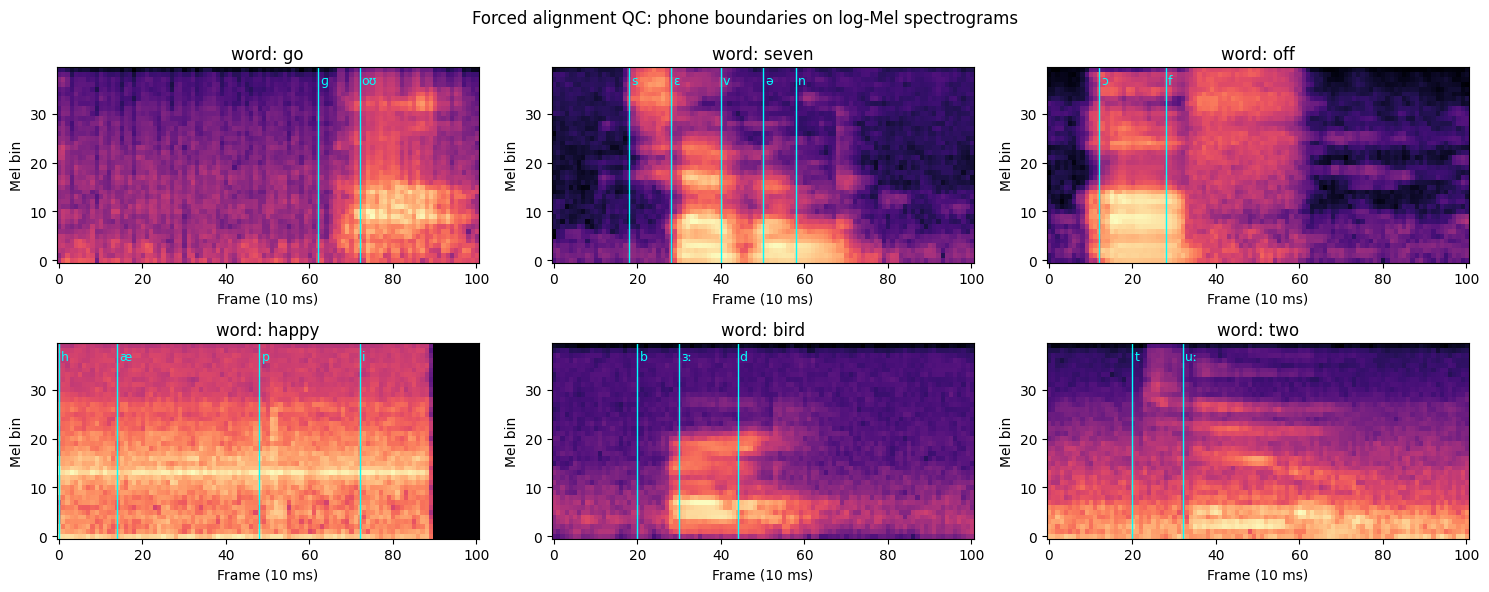

In [ ]:
# ============ 3b. Alignment QC (plots of random samples; figure text: English) ============
rng = np.random.default_rng(0)
sel = rng.choice(test_idx, 6, replace=False)
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, u in zip(axes.ravel(), sel):
    ax.imshow(np.asarray(X[u], np.float32), origin='lower', aspect='auto', cmap='magma')
    row = np.asarray(labels[u]); prev = None
    for t in range(CFG['n_frames']):
        if row[t] != prev:
            if row[t] >= 0:
                ax.axvline(t, color='cyan', lw=1)
                ax.text(t + 0.5, CFG['n_mels'] - 4, PHONES[row[t]],
                        color='cyan', fontsize=9)
            prev = row[t]
    ax.set_title('word: %s' % WORDS[y[u]])
    ax.set_xlabel('Frame (10 ms)'); ax.set_ylabel('Mel bin')
plt.suptitle('Forced alignment QC: phone boundaries on log-Mel spectrograms')
plt.tight_layout(); plt.show()
# Recommendation: inspect 50 or more samples by eye and report the fraction of bad utterances.


## 4. Activation dump (4 stages, one forward pass)

- SAE input = the **flatten(C×F)** vector of each time frame. Dimensions per stage for τ=3: S1=480, S2=360, S3=240, S4=300. The time axis has 101 frames in every stage, so all stages share the same frame-to-phone mapping.
- Train dump: 20,000 random utterances for SAE training (12,000 for τ=8). Test dump: the full test set, for analysis and metrics.
- Later stages have large receptive fields because of temporal dilation. Therefore, frames near phone boundaries are excluded from the analysis by a per-stage margin (`MARGINS`).

In [ ]:
# ============ 4. Activation dump ============
DUMP_DIR = '/content/act_dump'
os.makedirs(DUMP_DIR, exist_ok=True)
MARGINS = [1, 1, 2, 3]            # [FIX v2] boundary margin; the old [2,3,5,8] was too large for phone lengths (5-15 frames)
N_SAE_TRAIN_UTTS = {1: 20000, 3: 20000, 6: 12000, 8: 12000}

def stage_dims(model):
    with torch.no_grad():
        _, fs = model(torch.zeros(1, 1, CFG['n_mels'], CFG['n_frames'], device=device),
                      return_stages=True)
    return [(int(f.shape[1]), int(f.shape[2])) for f in fs]      # (C, F)

def dump_activations(tau, model, utt_idx, tag):
    utt_idx = np.asarray(utt_idx)
    paths = [os.path.join(DUMP_DIR, 'tau%d_s%d_%s.npy' % (tau, s, tag)) for s in range(4)]
    meta_p = os.path.join(DUMP_DIR, 'tau%d_%s_meta.json' % (tau, tag))
    if os.path.exists(meta_p) and all(os.path.exists(p) for p in paths):
        return paths, json.load(open(meta_p))
    dims = stage_dims(model)
    nrows = len(utt_idx) * CFG['n_frames']
    mms = [np.lib.format.open_memmap(p, mode='w+', dtype=np.float16, shape=(nrows, c * f))
           for p, (c, f) in zip(paths, dims)]
    B = 256; r = 0; t0 = time.time()
    model.eval()
    for i0 in range(0, len(utt_idx), B):
        ids = utt_idx[i0:i0 + B]
        xb = torch.from_numpy(np.asarray(X[ids], np.float32)).to(device)[:, None]
        with torch.no_grad():
            _, fs = model(xb, return_stages=True)
        for s, f in enumerate(fs):
            v = f.permute(0, 3, 1, 2).reshape(f.shape[0] * f.shape[3], -1)
            mms[s][r:r + v.shape[0]] = v.half().cpu().numpy()
        r += len(ids) * CFG['n_frames']
        if (i0 // B) % 20 == 0:
            print('dump tau%d %s: %d/%d  %.0fs' % (tau, tag, i0, len(utt_idx), time.time() - t0))
    for mm in mms:
        mm.flush()
    meta = dict(utt_idx=[int(u) for u in utt_idx], dims=dims)
    json.dump(meta, open(meta_p, 'w'))
    return paths, meta

def frame_phone_labels(utt_idx):
    return np.asarray(labels[np.asarray(utt_idx)]).reshape(-1)   # (n_utt * 101,)

def boundary_mask(utt_idx, margin):
    # True = frames that are at least `margin` frames away from a boundary (used in analysis)
    L = np.asarray(labels[np.asarray(utt_idx)])
    ch = np.zeros(L.shape, bool)
    ch[:, 1:] = L[:, 1:] != L[:, :-1]
    bad = ch.copy()
    for d in range(1, margin + 1):
        bad[:, :-d] |= ch[:, d:]
        bad[:, d:]  |= ch[:, :-d]
    return (~bad).reshape(-1)

rng = np.random.default_rng(0)
DUMPS = {}
for tau, m in MODELS.items():
    n_u = min(N_SAE_TRAIN_UTTS.get(tau, 20000), len(train_idx))
    utts = np.sort(rng.choice(train_idx, n_u, replace=False))
    DUMPS[(tau, 'train')] = dump_activations(tau, m, utts, 'train')
    DUMPS[(tau, 'test')]  = dump_activations(tau, m, test_idx, 'test')
print('dump done. stage dims per tau:', {t: DUMPS[(t, 'train')][1]['dims'] for t in MODELS})


dump tau1 train: 0/20000  0s
dump tau1 train: 5120/20000  9s
dump tau1 train: 10240/20000  11s
dump tau1 train: 15360/20000  14s
dump tau1 test: 0/11005  0s
dump tau1 test: 5120/11005  2s
dump tau1 test: 10240/11005  9s
dump tau3 train: 0/20000  0s
dump tau3 train: 5120/20000  6s
dump tau3 train: 10240/20000  13s
dump tau3 train: 15360/20000  26s
dump tau3 test: 0/11005  0s
dump tau3 test: 5120/11005  20s
dump tau3 test: 10240/11005  30s
dump done. stage dims per tau: {1: [(8, 20), (12, 10), (16, 5), (20, 5)], 3: [(24, 20), (36, 10), (48, 5), (60, 5)]}


## 5. TopK SAE + common metric battery

- TopK SAE: `z = ReLU(TopK((x − b_dec) Wᵉ + bᵉ))`. The decoder rows are renormalized to unit norm after every step.
- Input normalization: the input is divided by a per-stage scalar `scale = E‖x‖₂ / √d`. (It is multiplied back when the reconstruction is patched into the model.)
- Metrics: **FVU** (1 − explained variance ratio), **L0** (= k), **dead fraction**, **accuracy drop from the recon patch**, and **phone purity/coverage** (based on the best F1 of each latent, after the boundary margin is excluded).

In [ ]:
# ============ 5a. TopK SAE ============
class TopKSAE(nn.Module):
    def __init__(self, d, m, k):
        super().__init__()
        self.d, self.m, self.k = d, m, k
        self.W_enc = nn.Parameter(torch.randn(d, m) / math.sqrt(d))
        self.b_enc = nn.Parameter(torch.zeros(m))
        self.W_dec = nn.Parameter(F.normalize(torch.randn(m, d), dim=1))
        self.b_dec = nn.Parameter(torch.zeros(d))
    def encode(self, x):
        a = (x - self.b_dec) @ self.W_enc + self.b_enc
        v, i = torch.topk(a, self.k, dim=-1)
        return F.relu(v), i
    def decode(self, v, i):
        return torch.einsum('bk,bkd->bd', v, self.W_dec[i]) + self.b_dec
    def forward(self, x):
        v, i = self.encode(x)
        return self.decode(v, i), v, i
    @torch.no_grad()
    def renorm(self):
        self.W_dec.data = F.normalize(self.W_dec.data, dim=1)

def train_sae(act_path, d, m, k, seed, epochs=3, bs=4096, lr=1e-3, chunk=65536):
    seed_all(seed)
    A = np.load(act_path, mmap_mode='r')
    n = A.shape[0]
    rs = np.random.default_rng(seed)
    samp = np.asarray(A[np.sort(rs.choice(n, min(100000, n), replace=False))], np.float32)
    scale = float(np.linalg.norm(samp, axis=1).mean() / math.sqrt(d))
    sae = TopKSAE(d, m, k).to(device)
    opt = torch.optim.Adam(sae.parameters(), lr=lr)
    fire = torch.zeros(m, dtype=torch.long, device=device)
    t0 = time.time()
    for ep in range(epochs):
        if ep == epochs - 1:
            fire.zero_()                       # dead latents are judged on the last epoch
        starts = np.arange(0, n, chunk); rs.shuffle(starts)
        tot = cnt = 0.0
        for c0 in starts:
            xb_np = np.asarray(A[c0:c0 + chunk], np.float32)
            xb_all = torch.from_numpy(xb_np).to(device) / scale
            perm = torch.randperm(xb_all.shape[0], device=device)
            for b0 in range(0, xb_all.shape[0], bs):
                x = xb_all[perm[b0:b0 + bs]]
                xr, v, i = sae(x)
                loss = F.mse_loss(xr, x)
                opt.zero_grad(set_to_none=True)
                loss.backward(); opt.step(); sae.renorm()
                with torch.no_grad():
                    fire.scatter_add_(0, i[v > 0].flatten(),
                                      torch.ones_like(i[v > 0].flatten()))
                tot += loss.item(); cnt += 1
        print('  sae ep %d  mse %.4f  %.0fs' % (ep, tot / max(cnt, 1), time.time() - t0))
    dead_frac = float((fire == 0).float().mean().item())
    return sae, scale, dead_frac

@torch.no_grad()
def fvu(sae, act_path, scale, n_eval=200000, bs=8192):
    A = np.load(act_path, mmap_mode='r')
    n = min(n_eval, A.shape[0])
    se = 0.0; sx = 0.0; sx2 = 0.0; cnt = 0
    mean = torch.from_numpy(np.asarray(A[:n:max(1, n // 20000)], np.float32)).mean(0).to(device) / scale
    for i0 in range(0, n, bs):
        x = torch.from_numpy(np.asarray(A[i0:i0 + bs], np.float32)).to(device) / scale
        xr, _, _ = sae(x)
        se += ((x - xr) ** 2).sum().item()
        sx2 += ((x - mean) ** 2).sum().item()
        cnt += x.numel()
    return se / max(sx2, 1e-9)


@torch.no_grad()
def est_dead_frac(sae, act_path, scale, n_eval=200000, bs=8192):
    # [FIX v2] when an old ckpt is reused, estimate the dead fraction from a sample
    A = np.load(act_path, mmap_mode='r')
    n = min(n_eval, A.shape[0])
    fired = torch.zeros(sae.m, dtype=torch.bool, device=device)
    for i0 in range(0, n, bs):
        x = torch.from_numpy(np.asarray(A[i0:i0 + bs], np.float32)).to(device) / scale
        v, i = sae.encode(x)
        fired[i[v > 0].unique()] = True
    return float((~fired).float().mean().item())


In [ ]:
# ============ 5b. Phone selectivity metrics ============
def phone_latent_counts(sae, act_path, scale, lab, valid, bs=8192):
    # co-occurrence: (latent fires, phone) counts on valid frames
    A = np.load(act_path, mmap_mode='r')
    m = sae.m
    co  = torch.zeros(m * P, dtype=torch.float64, device=device)
    fj  = torch.zeros(m, dtype=torch.float64, device=device)
    npk = torch.zeros(P, dtype=torch.float64, device=device)
    for i0 in range(0, A.shape[0], bs):
        l = lab[i0:i0 + bs]
        vm = valid[i0:i0 + bs] & (l >= 0)
        if not vm.any():
            continue
        x = torch.from_numpy(np.asarray(A[i0:i0 + bs], np.float32)[vm]).to(device) / scale
        lt = torch.from_numpy(l[vm].astype(np.int64)).to(device)
        with torch.no_grad():
            v, idx = sae.encode(x)
        fired = v > 0
        li = idx[fired]
        pi_ = lt[:, None].expand_as(idx)[fired]
        ones = torch.ones_like(li, dtype=torch.float64)
        co.scatter_add_(0, li * P + pi_, ones)
        fj.scatter_add_(0, li, ones)
        npk.scatter_add_(0, lt, torch.ones_like(lt, dtype=torch.float64))
    return co.view(m, P).cpu().numpy(), fj.cpu().numpy(), npk.cpu().numpy()

def f1_matrix(co, fj, npk):
    prec = co / np.maximum(fj[:, None], 1.0)
    rec  = co / np.maximum(npk[None, :], 1.0)
    return 2 * prec * rec / np.maximum(prec + rec, 1e-9)

def purity_coverage(F1, fj, thr=0.5, min_fire=50):
    alive = fj >= min_fire
    if not alive.any():
        return 0.0, 0.0, F1.max(1)
    best = F1.max(1)
    purity   = float((best[alive] >= thr).mean())
    coverage = float((F1[alive].max(0) >= thr).mean())
    return purity, coverage, best


In [ ]:
# ============ 5c. Patch-back utilities (shared by recon / ablation / steering) ============
@contextmanager
def stage_patch(model, stage_idx, edit_fn):
    h = model.stages[stage_idx].register_forward_hook(
        lambda mod, inp, out: edit_fn(out))
    try:
        yield
    finally:
        h.remove()

def make_recon_fn(sae, scale, ablate_ids=None, steer=None):
    # steer: (dvec[d tensor], alpha, holder)  holder['m'] = (B,T) bool mask of the current batch
    ab = None
    if ablate_ids is not None and len(ablate_ids) > 0:
        ab = torch.as_tensor(np.asarray(sorted(ablate_ids), dtype=np.int64), device=device)
    def fn(out):
        Bc, C, Fq, T = out.shape
        x = out.permute(0, 3, 1, 2).reshape(-1, C * Fq).float() / scale
        with torch.no_grad():
            v, i = sae.encode(x)
            if ab is not None:
                v = v * (~torch.isin(i, ab)).float()
            xr = sae.decode(v, i)
            if steer is not None:
                dvec, alpha, holder = steer
                msk = holder['m'].reshape(-1).float().to(device)
                xr = xr + msk[:, None] * (alpha * dvec)[None, :]
        xr = xr * scale
        return xr.view(Bc, T, C, Fq).permute(0, 2, 3, 1).to(out.dtype)
    return fn

@torch.no_grad()
def eval_patched(model, stage_idx, fn, idx=None, B=256):
    # returns overall acc, per-word acc, preds
    idx = test_idx if idx is None else np.asarray(idx)
    preds = np.zeros(len(idx), np.int64)
    ctx = stage_patch(model, stage_idx, fn) if fn is not None else nullcontext()
    model.eval()
    with ctx:
        for i0 in range(0, len(idx), B):
            ids = idx[i0:i0 + B]
            xb = torch.from_numpy(np.asarray(X[ids], np.float32)).to(device)[:, None]
            preds[i0:i0 + len(ids)] = model(xb).argmax(1).cpu().numpy()
    yy = y[idx].astype(np.int64)
    acc = float((preds == yy).mean())
    pw = np.array([(preds[yy == c] == c).mean() if (yy == c).any() else np.nan
                   for c in range(len(WORDS))])
    return acc, pw, preds

CLEAN_ACC = {}
def clean_acc(tau):
    if tau not in CLEAN_ACC:
        CLEAN_ACC[tau] = eval_patched(MODELS[tau], 0, None)[0]
    return CLEAN_ACC[tau]

def ablation_topset(F1, phone, topn=8):
    return np.argsort(-F1[:, P2I[phone]])[:topn]

def ablation_selectivity(model, stage_idx, sae, scale, latset, phone, base_pw):
    fn = make_recon_fn(sae, scale, ablate_ids=latset)
    _, pw, _ = eval_patched(model, stage_idx, fn)
    has = np.array([phone in WORD_PHONES[w] for w in WORDS])
    dd = base_pw - pw
    return float(np.nanmean(dd[has]) - np.nanmean(dd[~has])), pw


## 6. Hub-and-spoke runner — **all numeric comparisons at once**

- **The `MAIN` cell is the only reference point.** Each spoke changes exactly one axis of MAIN (star design). 15 runs in total.
- Every run computes the common metric battery and appends one row to `results/sae_runs.csv` on Drive. **Finished runs (a CSV row and an SAE checkpoint exist) are skipped automatically.** So if the session disconnects, rerunning this cell continues from where it stopped.
- The probe phones (3 phones for the lightweight ablation) are selected automatically from the F1 results of the MAIN run and are fixed in `results/probe_phones.json`. All later spokes use the same probes.
- **Changing MAIN**: if the stage comparison shows a higher purity at another stage, change `MAIN['stage']` and rerun this cell. Because of the run_id scheme, finished runs are reused as they are. (Whether the probe phones are kept or reselected depends on whether `probe_phones.json` is deleted.)
- By design, the τ=8 spoke computes only the Phase 1–2 metrics, without interventions (ablation).

In [ ]:
# ============ 6a. Experiment definition ============
MAIN = dict(tau=3, stage=3, exp=16, k=16, seed=0)

STAGE_SPOKES = [0, 1, 3]
EXP_SPOKES   = [4, 8, 32, 64]
K_SPOKES     = [4, 8, 32]
SEED_SPOKES  = [1, 2]
TAU_SPOKES   = [1, 8]

def build_runs():
    runs = [dict(MAIN)]                                    # MAIN first (the probes are selected from it)
    runs += [{**MAIN, 'stage': s} for s in STAGE_SPOKES]
    runs += [{**MAIN, 'exp': e} for e in EXP_SPOKES]
    runs += [{**MAIN, 'k': kk} for kk in K_SPOKES]
    runs += [{**MAIN, 'seed': sd} for sd in SEED_SPOKES]
    runs += [{**MAIN, 'tau': t} for t in TAU_SPOKES]
    return runs

def run_id(c):
    return 'tau%d_s%d_x%d_k%d_seed%d' % (c['tau'], c['stage'], c['exp'], c['k'], c['seed'])

RESULTS_CSV = os.path.join(RESULTS_DIR, 'sae_runs_v2.csv')      # [FIX v2] labels changed, so the metric cache is not used
PROBES_JSON = os.path.join(RESULTS_DIR, 'probe_phones_v2.json')  # [FIX v2]

def sae_ckpt_path(rid):
    return os.path.join(SAE_DIR, rid + '.pt')

import pandas as pd
def load_results():
    return pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()

def append_result(row):
    df = load_results()
    if len(df):
        df = df[df.run_id != row['run_id']]
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    tmp = RESULTS_CSV + '.tmp'
    df.to_csv(tmp, index=False)
    os.replace(tmp, RESULTS_CSV)

def load_sae(rid):
    ck = torch.load(sae_ckpt_path(rid), map_location=device, weights_only=False)
    sae = TopKSAE(ck['d'], ck['m'], ck['k']).to(device)
    sae.load_state_dict(ck['state'])
    return sae.eval(), ck['scale']


In [ ]:
# ============ 6b. Function that executes one run ============
# [FIX v2] The alignment labels changed, so all metrics (purity/coverage/selectivity)
# must be recomputed. However, SAE training does not depend on the labels, so an
# existing SAE ckpt is reused if there is one.
def execute_run(cfg, force=False):
    rid = run_id(cfg)
    df = load_results()
    if (not force and len(df) and (df.run_id == rid).any()
            and os.path.exists(sae_ckpt_path(rid))):
        print('skip (cached):', rid)
        return
    if cfg['tau'] not in MODELS:
        print('skip (no host checkpoint): tau=%d' % cfg['tau'])
        return
    model = MODELS[cfg['tau']]
    tr_paths, tr_meta = DUMPS[(cfg['tau'], 'train')]
    te_paths, te_meta = DUMPS[(cfg['tau'], 'test')]
    s = cfg['stage']
    C, Fq = tr_meta['dims'][s]
    d = C * Fq; m = d * cfg['exp']
    print('== %s  (d=%d, m=%d, k=%d) ==' % (rid, d, m, cfg['k']))

    # (1) train the SAE, or reuse an existing ckpt
    ck_path = sae_ckpt_path(rid)
    if os.path.exists(ck_path) and not force:
        ck = torch.load(ck_path, map_location=device, weights_only=False)
        sae = TopKSAE(ck['d'], ck['m'], ck['k']).to(device).eval()
        sae.load_state_dict(ck['state'])
        scale = ck['scale']
        dead = ck.get('dead_frac', None)
        if dead is None:                       # old ckpts do not store dead_frac
            dead = est_dead_frac(sae, tr_paths[s], scale)
        print('   (reusing existing SAE ckpt; recomputing metrics only)')
    else:
        sae, scale, dead = train_sae(tr_paths[s], d, m, cfg['k'], cfg['seed'])
        torch.save(dict(state=sae.state_dict(), d=d, m=m, k=cfg['k'],
                        scale=scale, dead_frac=dead, cfg=cfg), ck_path)

    # (2) reconstruction quality
    fv = fvu(sae, te_paths[s], scale)

    # (3) phone selectivity
    lab = frame_phone_labels(te_meta['utt_idx'])
    valid = boundary_mask(te_meta['utt_idx'], MARGINS[s])
    co, fj, npk = phone_latent_counts(sae, te_paths[s], scale, lab, valid)
    F1 = f1_matrix(co, fj, npk)
    pur, cov, best = purity_coverage(F1, fj)

    # (4) accuracy drop from the recon patch
    acc_r, pw_r, _ = eval_patched(model, s, make_recon_fn(sae, scale))
    row = dict(run_id=rid, **cfg, d=d, m=m, fvu=fv, dead_frac=dead,
               purity=pur, coverage=cov,
               clean_acc=clean_acc(cfg['tau']), recon_acc=acc_r,
               recon_acc_drop=clean_acc(cfg['tau']) - acc_r)

    # (5) for the MAIN run, fix the probe phones here (frame count >= 2000, top 3 by best F1)
    if rid == run_id(MAIN) and not os.path.exists(PROBES_JSON):
        okp = npk >= 2000
        assert okp.any(), ('No phone has 2000 or more valid frames. '
                           'Check the alignment (3a) or MARGINS (4).')  # [FIX v2] fail loudly instead of degrading silently
        score = np.where(okp, F1.max(0), -1.0)
        probes = [PHONES[i] for i in np.argsort(-score)[:3]]
        json.dump({'phones': probes}, open(PROBES_JSON, 'w'))
        print('probe phones fixed:', probes)

    # (6) lightweight ablation (3 probes; skipped for tau=8 by design)
    if cfg['tau'] != 8 and os.path.exists(PROBES_JSON):
        probes = json.load(open(PROBES_JSON))['phones']
        sels = []
        for ph in probes:
            latset = ablation_topset(F1, ph, topn=8)
            sel, _ = ablation_selectivity(model, s, sae, scale, latset, ph, pw_r)
            sels.append(sel)
            row['sel_' + ph] = sel
        row['probe_selectivity_mean'] = float(np.mean(sels))
    append_result(row)
    print('   fvu %.3f | dead %.2f | purity %.3f | coverage %.3f | recon drop %.4f'
          % (fv, dead, pur, cov, row['recon_acc_drop']))


In [ ]:
# ============ 6c. Execute all runs (resumable) ============
for cfg in build_runs():
    execute_run(cfg)

df = load_results()
cols = ['run_id', 'fvu', 'dead_frac', 'purity', 'coverage',
        'recon_acc_drop', 'probe_selectivity_mean']
print(df[[c for c in cols if c in df.columns]].to_string(index=False))


skip (cached): tau3_s3_x16_k16_seed0
skip (cached): tau3_s0_x16_k16_seed0
skip (cached): tau3_s1_x16_k16_seed0
skip (cached): tau3_s3_x16_k16_seed0
== tau3_s3_x4_k16_seed0  (d=300, m=1200, k=16) ==
  sae ep 0  mse 0.5874  12s
  sae ep 1  mse 0.1949  20s
  sae ep 2  mse 0.1221  28s
   fvu 0.096 | dead 0.05 | purity 0.142 | coverage 0.439 | recon drop 0.0040
== tau3_s3_x8_k16_seed0  (d=300, m=2400, k=16) ==
  sae ep 0  mse 0.5660  9s
  sae ep 1  mse 0.1789  18s
  sae ep 2  mse 0.1126  28s
   fvu 0.088 | dead 0.10 | purity 0.135 | coverage 0.439 | recon drop 0.0033
== tau3_s3_x32_k16_seed0  (d=300, m=9600, k=16) ==
  sae ep 0  mse 0.5464  20s
  sae ep 1  mse 0.1562  40s
  sae ep 2  mse 0.0961  60s
   fvu 0.078 | dead 0.23 | purity 0.139 | coverage 0.610 | recon drop 0.0023
== tau3_s3_x64_k16_seed0  (d=300, m=19200, k=16) ==
  sae ep 0  mse 0.5453  38s
  sae ep 1  mse 0.1458  75s
  sae ep 2  mse 0.0881  112s
   fvu 0.072 | dead 0.27 | purity 0.144 | coverage 0.659 | recon drop 0.0023
== ta

In [ ]:
# ============ 7. Load the MAIN run (common entry point for the analysis cells below) ============
MAIN_RID = run_id(MAIN)
sae_M, scale_M = load_sae(MAIN_RID)
model_M = MODELS[MAIN['tau']]
stage_M = MAIN['stage']
te_paths_M, te_meta_M = DUMPS[(MAIN['tau'], 'test')]
lab_M   = frame_phone_labels(te_meta_M['utt_idx'])
valid_M = boundary_mask(te_meta_M['utt_idx'], MARGINS[stage_M])
co_M, fj_M, npk_M = phone_latent_counts(sae_M, te_paths_M[stage_M], scale_M, lab_M, valid_M)
F1_M = f1_matrix(co_M, fj_M, npk_M)
acc_recon_M, pw_recon_M, _ = eval_patched(model_M, stage_M, make_recon_fn(sae_M, scale_M))
PROBES = json.load(open(PROBES_JSON))['phones'] if os.path.exists(PROBES_JSON) else []
print('MAIN:', MAIN_RID, '| probes:', PROBES,
      '| recon acc %.4f (clean %.4f)' % (acc_recon_M, clean_acc(MAIN['tau'])))


MAIN: tau3_s3_x16_k16_seed0 | probes: [] | recon acc 0.9687 (clean 0.9716)


## 8. Baseline comparison (MAIN): SAE vs raw neurons / PCA / random projection

The distributions of the best F1 per unit are compared on the same activations. For fairness, each baseline unit uses whichever of several fire-rate thresholds (0.5%, 2%, 8%) is **most favorable to that unit**. (This setting is generous to the baselines, so a claim that the SAE is better would be stronger.) A Mann–Whitney U test is included.

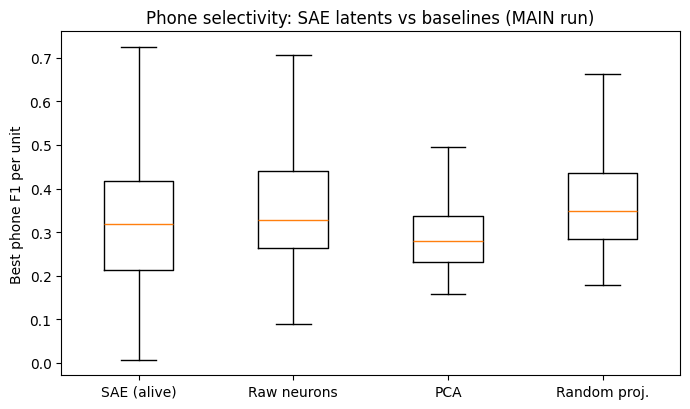

SAE > Raw neurons    Mann-Whitney U=5.46e+04  p=0.998  (median 0.319 vs 0.328)
SAE > PCA            Mann-Whitney U=5.74e+04  p=0.0553  (median 0.319 vs 0.280)
SAE > Random proj.   Mann-Whitney U=5.01e+04  p=1  (median 0.319 vs 0.348)


In [ ]:
# ============ 8. Baseline comparison ============
from scipy.stats import mannwhitneyu

def unit_best_f1(project, d_units, act_path, scale, lab, valid,
                 rates=(0.005, 0.02, 0.08), bs=8192, n_thr_sample=200000):
    A = np.load(act_path, mmap_mode='r')
    n = A.shape[0]
    samp = torch.from_numpy(
        np.asarray(A[:min(n, n_thr_sample)], np.float32)).to(device) / scale
    z_np = project(samp).cpu().numpy()          # numpy quantile (torch.quantile has size limits)
    thrs = [torch.from_numpy(np.quantile(z_np, 1 - r, axis=0).astype(np.float32)).to(device)
            for r in rates]
    del z_np
    best = np.zeros((len(rates), d_units))
    for ri, thr in enumerate(thrs):
        co  = torch.zeros(d_units, P, dtype=torch.float64, device=device)
        fj  = torch.zeros(d_units, dtype=torch.float64, device=device)
        npk = torch.zeros(P, dtype=torch.float64, device=device)
        for i0 in range(0, n, bs):
            l = lab[i0:i0 + bs]
            vm = valid[i0:i0 + bs] & (l >= 0)
            if not vm.any():
                continue
            x = torch.from_numpy(np.asarray(A[i0:i0 + bs], np.float32)[vm]).to(device) / scale
            lt = torch.from_numpy(l[vm].astype(np.int64)).to(device)
            fires = (project(x) > thr[None, :]).double()
            oh = F.one_hot(lt, P).double()
            co += fires.T @ oh
            fj += fires.sum(0)
            npk += oh.sum(0)
        f1 = f1_matrix(co.cpu().numpy(), fj.cpu().numpy(), npk.cpu().numpy())
        best[ri] = f1.max(1)
    return best.max(0)

d_M = sae_M.d
ap = te_paths_M[stage_M]
seed_all(0)
Asub = torch.from_numpy(np.asarray(
    np.load(ap, mmap_mode='r')[:200000], np.float32)).to(device) / scale_M
mu_pca = Asub.mean(0, keepdim=True)
_, _, V = torch.pca_lowrank(Asub - mu_pca, q=min(d_M, 256))
Wrand = F.normalize(torch.randn(d_M, d_M, device=device), dim=0)

base_raw  = unit_best_f1(lambda x: x, d_M, ap, scale_M, lab_M, valid_M)
base_pca  = unit_best_f1(lambda x: (x - mu_pca) @ V, V.shape[1], ap, scale_M, lab_M, valid_M)
base_rand = unit_best_f1(lambda x: x @ Wrand, d_M, ap, scale_M, lab_M, valid_M)
sae_best  = F1_M.max(1)[fj_M >= 50]
assert len(sae_best) > 0, ('No alive latents (fj>=50). '
                           'Check the alignment (3a) and MARGINS (4).')  # [FIX v2] avoid printing NaN statistics without an error

fig, ax = plt.subplots(figsize=(7, 4.2))
data = [sae_best, base_raw, base_pca, base_rand]
names = ['SAE (alive)', 'Raw neurons', 'PCA', 'Random proj.']
try:                                            # [FIX v2] compatibility with matplotlib>=3.9
    ax.boxplot(data, tick_labels=names, showfliers=False)
except TypeError:
    ax.boxplot(data, labels=names, showfliers=False)
ax.set_ylabel('Best phone F1 per unit')
ax.set_title('Phone selectivity: SAE latents vs baselines (MAIN run)')
plt.tight_layout(); plt.show()

for nm, b in zip(names[1:], data[1:]):
    u, p = mannwhitneyu(sae_best, b, alternative='greater')
    print('SAE > %-13s  Mann-Whitney U=%.3g  p=%.3g  (median %.3f vs %.3f)'
          % (nm, u, p, np.median(sae_best), np.median(b)))


## 9. Spoke comparison figure — all axes in one figure

Rows = comparison axes (stage / expansion / L0 / seed / τ); columns = metrics. **Red star = the MAIN cell** (the same run in every row). Missing runs (for example, a τ without a checkpoint) are skipped automatically.

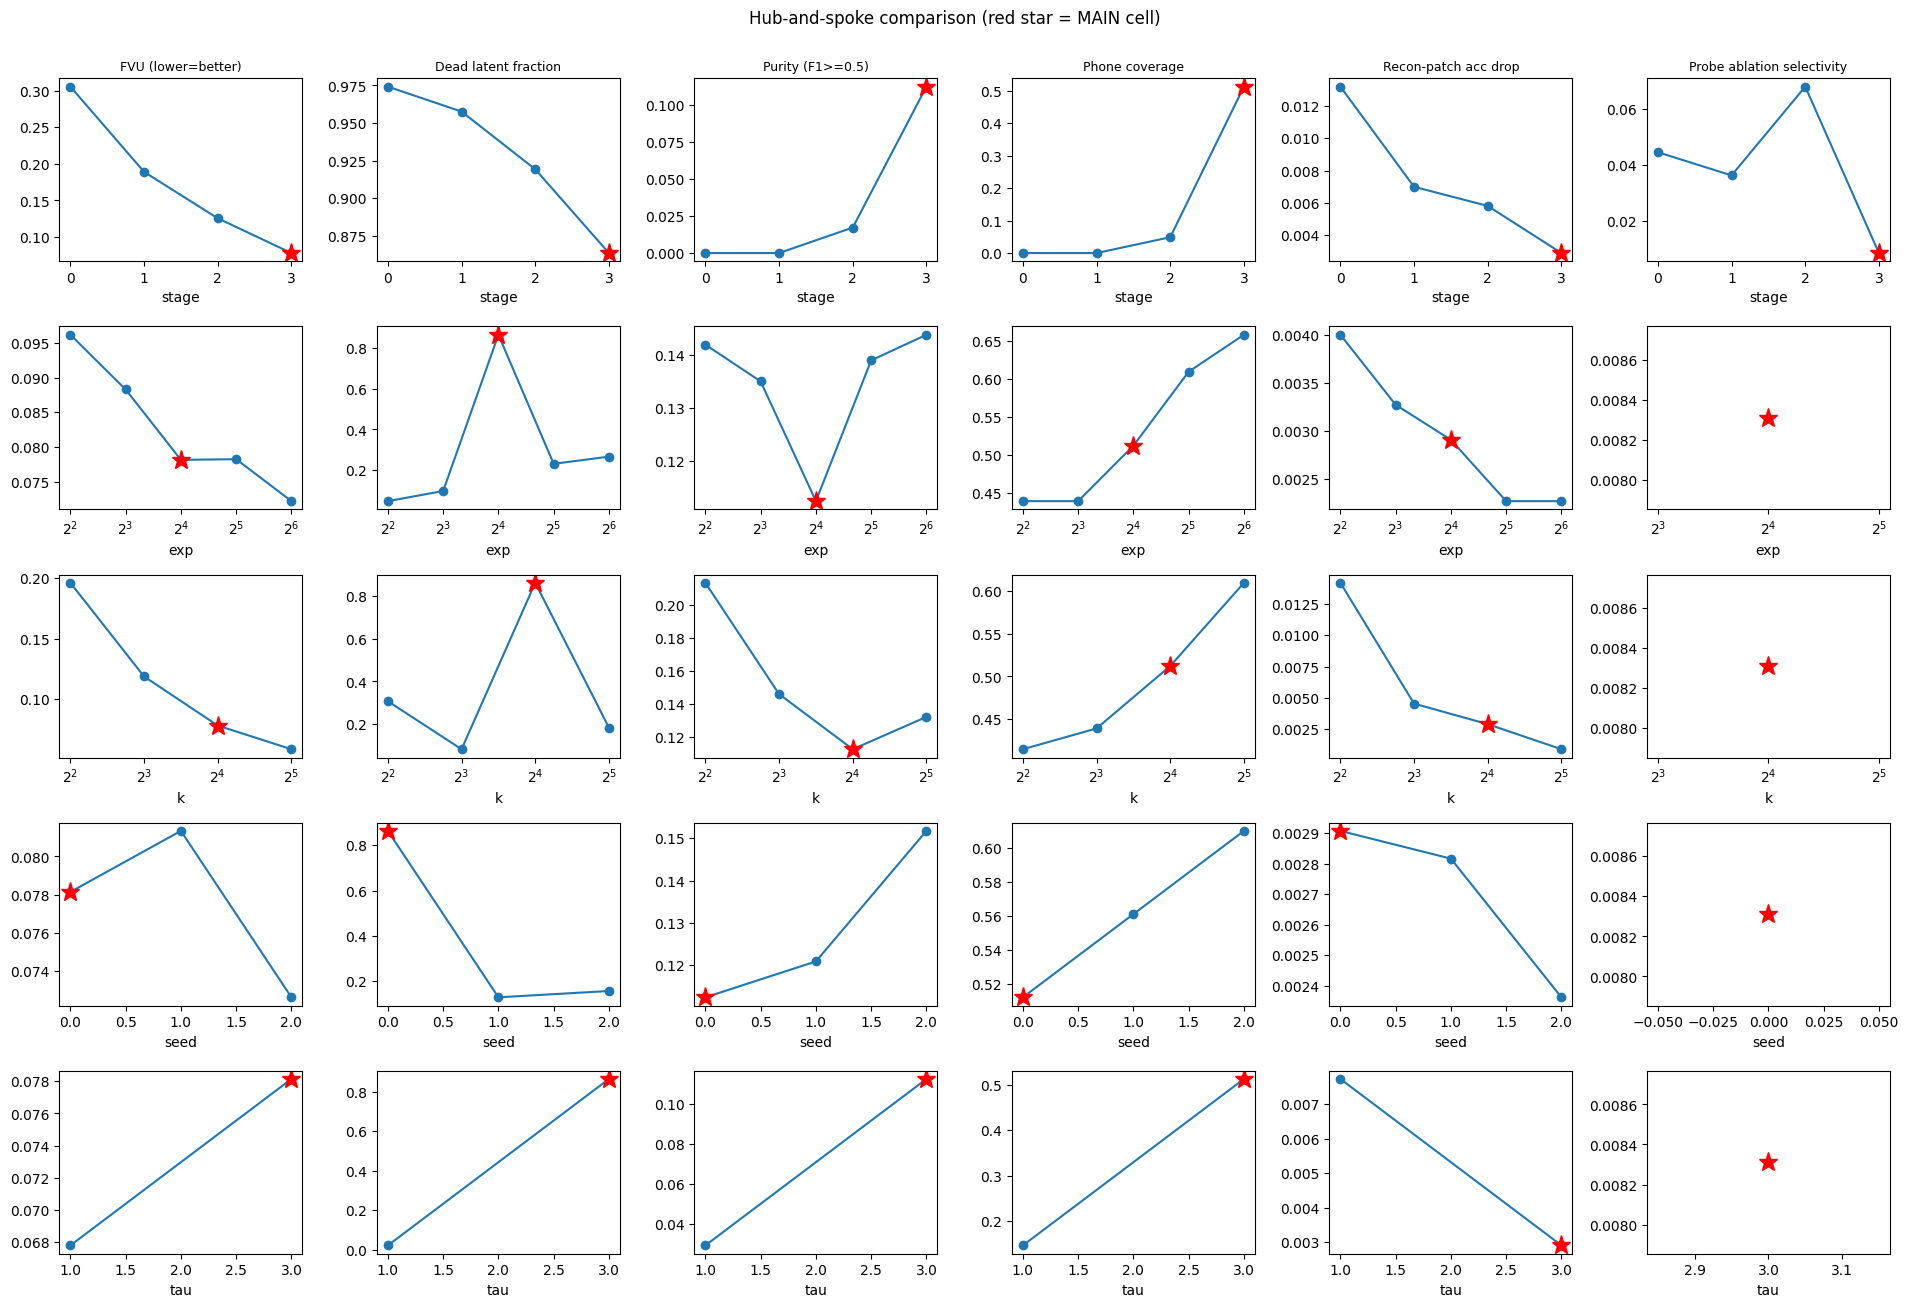

In [ ]:
# ============ 9. Spoke comparison grid ============
df = load_results().set_index('run_id')
AXES_SPEC = [('stage', [0, 1, 2, 3]),
             ('exp',   sorted(set([MAIN['exp']] + EXP_SPOKES))),
             ('k',     sorted(set([MAIN['k']] + K_SPOKES))),
             ('seed',  sorted(set([MAIN['seed']] + SEED_SPOKES))),
             ('tau',   sorted(set([MAIN['tau']] + TAU_SPOKES)))]
METRICS = [('fvu', 'FVU (lower=better)'),
           ('dead_frac', 'Dead latent fraction'),
           ('purity', 'Purity (F1>=0.5)'),
           ('coverage', 'Phone coverage'),
           ('recon_acc_drop', 'Recon-patch acc drop'),
           ('probe_selectivity_mean', 'Probe ablation selectivity')]

fig, axs = plt.subplots(len(AXES_SPEC), len(METRICS),
                        figsize=(3.2 * len(METRICS), 2.6 * len(AXES_SPEC)))
for r, (axis, vals) in enumerate(AXES_SPEC):
    pts = []
    for v in vals:
        rid = run_id({**MAIN, axis: v})
        if rid in df.index:
            pts.append((v, df.loc[rid]))
    for c, (mt, mtitle) in enumerate(METRICS):
        ax = axs[r][c]
        xs = [v for v, _ in pts]
        ys = [row[mt] if mt in row and pd.notna(row[mt]) else np.nan for _, row in pts]
        ax.plot(xs, ys, 'o-', color='C0')
        if MAIN[axis] in xs:
            j = xs.index(MAIN[axis])
            ax.plot([xs[j]], [ys[j]], 'r*', ms=14)
        ax.set_xlabel(axis)
        if r == 0:
            ax.set_title(mtitle, fontsize=9)
        if axis in ('exp', 'k'):
            ax.set_xscale('log', base=2)
fig.suptitle('Hub-and-spoke comparison (red star = MAIN cell)', y=1.002)
plt.tight_layout(); plt.show()


tau3_s3_x16_k16_seed0 vs tau3_s3_x16_k16_seed1 (alive 311 vs 287): mean max-cosine 0.510, frac>0.7: 0.093
tau3_s3_x16_k16_seed0 vs tau3_s3_x16_k16_seed2 (alive 311 vs 294): mean max-cosine 0.518, frac>0.7: 0.096


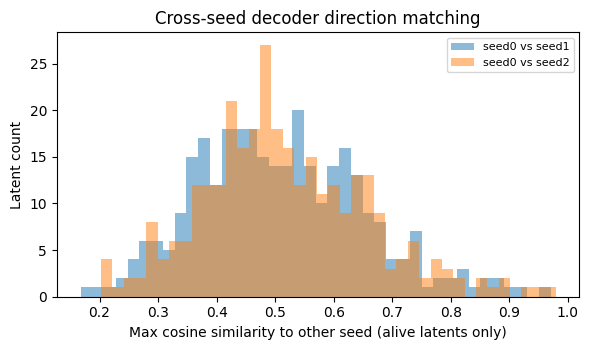

In [ ]:
# ============ 9b. Seed reproducibility: cross-seed matching of decoder directions ============
# [FIX v2] If dead latents (directions that keep their random initial values) are
# included in the matching, the mean max-cosine is strongly biased downward
# (dead 40-90%). So only latents that actually fire on utterances are compared.
@torch.no_grad()
def fire_counts(sae, act_path, scale, n_eval=100000, bs=8192):
    A = np.load(act_path, mmap_mode='r')
    n = min(n_eval, A.shape[0])
    cnt = torch.zeros(sae.m, dtype=torch.long, device=device)
    for i0 in range(0, n, bs):
        x = torch.from_numpy(np.asarray(A[i0:i0 + bs], np.float32)).to(device) / scale
        v, i = sae.encode(x)
        f = i[v > 0].flatten()
        cnt.scatter_add_(0, f, torch.ones_like(f))
    return cnt.cpu().numpy()

def decoder_match(rid_a, rid_b, act_path, min_fire=20):
    sa, sca = load_sae(rid_a)
    sb, scb = load_sae(rid_b)
    alive_a = fire_counts(sa, act_path, sca) >= min_fire
    alive_b = fire_counts(sb, act_path, scb) >= min_fire
    Wa = F.normalize(sa.W_dec.data[torch.from_numpy(alive_a).to(device)], dim=1)
    Wb = F.normalize(sb.W_dec.data[torch.from_numpy(alive_b).to(device)], dim=1)
    cos = Wa @ Wb.T
    return cos.max(1).values.cpu().numpy(), int(alive_a.sum()), int(alive_b.sum())

pairs = [(run_id(MAIN), run_id({**MAIN, 'seed': sd})) for sd in SEED_SPOKES]
fig, ax = plt.subplots(figsize=(6, 3.6))
for (ra, rb) in pairs:
    if os.path.exists(sae_ckpt_path(ra)) and os.path.exists(sae_ckpt_path(rb)):
        mc, na, nb = decoder_match(ra, rb, te_paths_M[stage_M])
        ax.hist(mc, bins=40, alpha=0.5, label='%s vs %s' % (ra[-5:], rb[-5:]))
        print('%s vs %s (alive %d vs %d): mean max-cosine %.3f, frac>0.7: %.3f'
              % (ra, rb, na, nb, mc.mean(), (mc > 0.7).mean()))
ax.set_xlabel('Max cosine similarity to other seed (alive latents only)')
ax.set_ylabel('Latent count')
ax.set_title('Cross-seed decoder direction matching')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 10. Full ablation suite (MAIN only) — H2: causal selectivity

For each target phone (frame count ≥1500 and max F1 ≥0.35; adjust if needed):
- Zero-ablate the top 8 latents → measure the change in per-word accuracy.
- **selectivity = Δ(words that contain the phone) − Δ(words that do not)** (reference = accuracy with the recon patch)
- Random-latent ablation is used as the control. (Note: the code samples random latents from the alive latents. It does not match their fire counts.)
- For the top 3 phones, a dose–response curve is computed (1 → 16 ablated latents).

phones under test (23): ['aɪ', 'aʊ', 'd', 'eɪ', 'f', 'iː', 'k', 'l', 'n', 'p', 's', 't', 'v', 'w', 'æ', 'ɑː', 'ɔ', 'ɛ', 'ɜː', 'ɡ', 'ɪ', 'ɹ', 'ʌ']
aɪ      selectivity 0.0927   random-control -0.0022
aʊ      selectivity 0.0158   random-control -0.0017
d       selectivity 0.0364   random-control -0.0003
eɪ      selectivity 0.0237   random-control -0.0003
f       selectivity 0.0042   random-control -0.0006
iː      selectivity 0.0179   random-control -0.0000
k       selectivity 0.0073   random-control -0.0008
l       selectivity 0.0054   random-control 0.0046
n       selectivity 0.0073   random-control -0.0009
p       selectivity 0.0995   random-control -0.0003
s       selectivity 0.0061   random-control 0.0021
t       selectivity 0.0016   random-control -0.0009
v       selectivity 0.2317   random-control -0.0003
w       selectivity 0.0116   random-control -0.0018
æ       selectivity 0.0001   random-control -0.0042
ɑː      selectivity 0.0011   random-control -0.0038
ɔ       selectivity 0.01

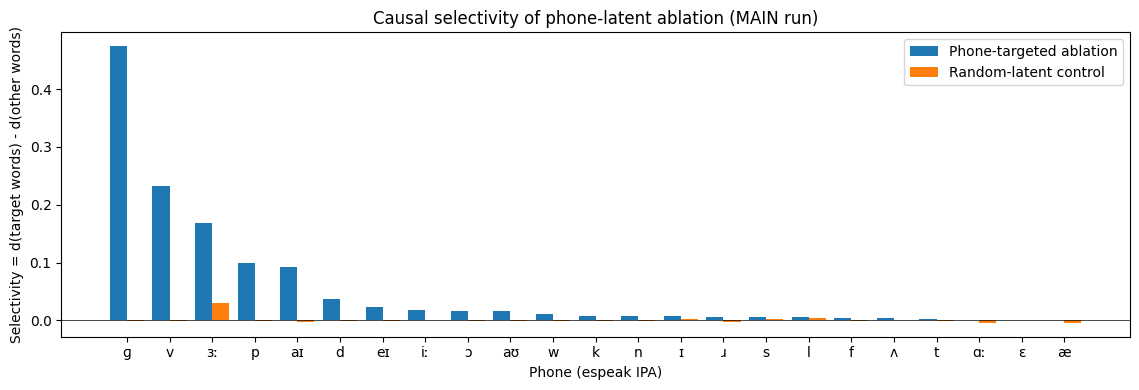

In [ ]:
# ============ 10a. Ablation selectivity per phone + random control ============
cand = [PHONES[p] for p in range(P)
        if npk_M[p] >= 1500 and F1_M[:, p].max() >= 0.35]
print('phones under test (%d):' % len(cand), cand)
assert len(cand) > 0, ('No candidate phones for ablation. After fixing the alignment/margins, '
                       'check that sections 6-7 were rerun.')  # [FIX v2]

alive_ids = np.where(fj_M >= 50)[0]
rng_ab = np.random.default_rng(0)
rows_ab = []
for ph in cand:
    latset = ablation_topset(F1_M, ph, topn=8)
    sel, pw = ablation_selectivity(model_M, stage_M, sae_M, scale_M, latset, ph, pw_recon_M)
    rnd = rng_ab.choice(alive_ids, size=len(latset), replace=False)
    sel_r, _ = ablation_selectivity(model_M, stage_M, sae_M, scale_M, rnd, ph, pw_recon_M)
    rows_ab.append((ph, sel, sel_r))
    print('%-6s  selectivity %.4f   random-control %.4f' % (ph, sel, sel_r))

abl_df = pd.DataFrame(rows_ab, columns=['phone', 'selectivity', 'random_control'])
abl_df = abl_df.sort_values('selectivity', ascending=False)
tmp = os.path.join(RESULTS_DIR, 'ablation_main.csv')
abl_df.to_csv(tmp + '.t', index=False); os.replace(tmp + '.t', tmp)

fig, ax = plt.subplots(figsize=(max(7, 0.5 * len(abl_df)), 4))
xpos = np.arange(len(abl_df))
ax.bar(xpos - 0.2, abl_df.selectivity, 0.4, label='Phone-targeted ablation')
ax.bar(xpos + 0.2, abl_df.random_control, 0.4, label='Random-latent control')
ax.set_xticks(xpos); ax.set_xticklabels(abl_df.phone)
ax.set_xlabel('Phone (espeak IPA)')
ax.set_ylabel('Selectivity = d(target words) - d(other words)')
ax.set_title('Causal selectivity of phone-latent ablation (MAIN run)')
ax.axhline(0, color='k', lw=0.5); ax.legend()
plt.tight_layout(); plt.show()


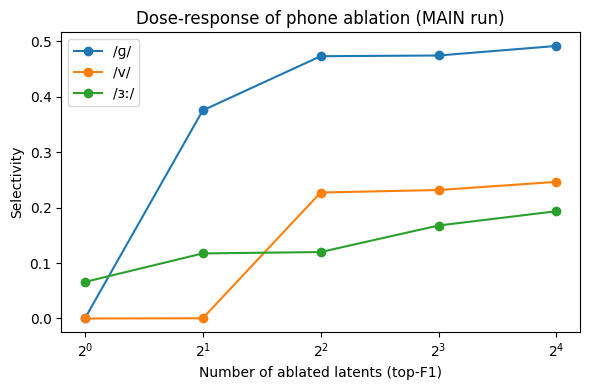

In [ ]:
# ============ 10b. Dose-response (top 3 phones) ============
top3 = list(abl_df.phone.head(3))
assert len(top3) > 0, 'The candidate phones from 10a are empty.'  # [FIX v2] prevents the direct cause of the IndexError in 10c
NTOPS = [1, 2, 4, 8, 16]
fig, ax = plt.subplots(figsize=(6, 4))
for ph in top3:
    ys = []
    for nt in NTOPS:
        latset = ablation_topset(F1_M, ph, topn=nt)
        sel, _ = ablation_selectivity(model_M, stage_M, sae_M, scale_M,
                                      latset, ph, pw_recon_M)
        ys.append(sel)
    ax.plot(NTOPS, ys, 'o-', label='/%s/' % ph)
ax.set_xscale('log', base=2)
ax.set_xlabel('Number of ablated latents (top-F1)')
ax.set_ylabel('Selectivity')
ax.set_title('Dose-response of phone ablation (MAIN run)')
ax.legend(); plt.tight_layout(); plt.show()


In [ ]:
# ============ 10c. Confusion shift: where misclassifications go when the top phone is ablated ============
ph = top3[0]
latset = ablation_topset(F1_M, ph, topn=8)
_, _, preds_ab = eval_patched(model_M, stage_M,
                              make_recon_fn(sae_M, scale_M, ablate_ids=latset))
_, _, preds_rc = eval_patched(model_M, stage_M, make_recon_fn(sae_M, scale_M))
yy = y[test_idx].astype(np.int64)
tgt_words = [i for i, w in enumerate(WORDS) if ph in WORD_PHONES[w]]

def overlap(w1, w2):
    a, b = set(WORD_PHONES[w1]), set(WORD_PHONES[w2])
    return len(a & b) / max(len(a | b), 1)

print('Ablated phone: /%s/  target words: %s' % (ph, [WORDS[i] for i in tgt_words]))
shift_overlaps, base_overlaps = [], []
for c in tgt_words:
    mk = (yy == c) & (preds_rc == c) & (preds_ab != c)   # only utterances that became wrong because of the ablation
    if mk.sum() == 0:
        continue
    dest, cnts = np.unique(preds_ab[mk], return_counts=True)
    order = np.argsort(-cnts)
    tops = ', '.join('%s(%d)' % (WORDS[dest[i]], cnts[i]) for i in order[:3])
    print('  %-10s -> %s' % (WORDS[c], tops))
    for dp, ct in zip(dest, cnts):
        shift_overlaps += [overlap(WORDS[c], WORDS[dp])] * int(ct)
    base_overlaps += [overlap(WORDS[c], WORDS[o]) for o in range(35) if o != c]
if shift_overlaps:
    print('mean phone overlap: shifted-to %.3f  vs all-words baseline %.3f'
          % (np.mean(shift_overlaps), np.mean(base_overlaps)))


Ablated phone: /ɡ/  target words: ['dog', 'go']
  dog        -> house(100), down(30), go(29)
mean phone overlap: shifted-to 0.078  vs all-words baseline 0.043


## 11. Steering (MAIN only) — H3: minimal-pair manipulation

The decoder direction of the target phone is added, scaled by α, to the **segment of the word-initial phone** (from the alignment) in utterances of the source word. The logit difference and the flip rate are measured. Injecting a random direction is the control.

Pairs: `no→go`, `three→tree`, `nine→five` (the direction of the target word's initial phone is injected into source utterances). (In v2, `four→forward` was replaced by `nine→five`; see the comment in the code cell.)

typical latent activation V_MEAN = 2.791
no->go [phone direction] flip@max-alpha: 0.000
no->go [random direction] flip@max-alpha: 0.000
three->tree [phone direction] flip@max-alpha: 0.017
three->tree [random direction] flip@max-alpha: 0.012
nine->five [phone direction] flip@max-alpha: 0.007
nine->five [random direction] flip@max-alpha: 0.002


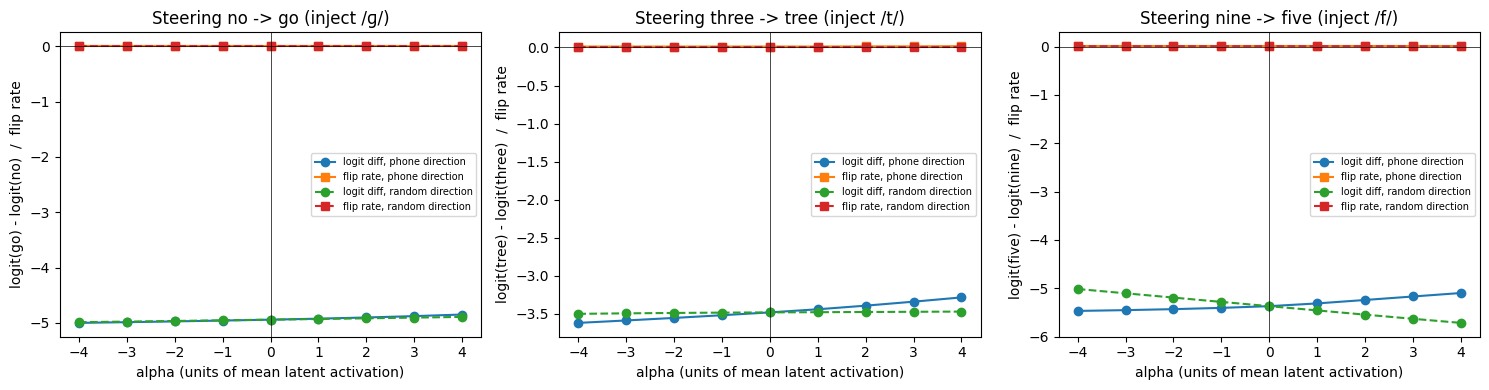

In [ ]:
# ============ 11. Steering experiment ============
# [FIX v2] In ('four','forward'), both words begin with /f/. So the pair does not
# fit this design, which replaces the word-initial phone with the target's, and it
# actually raised an AssertionError at assert p_src0 != p_tgt0. It is replaced by
# the near-minimal pair ('nine','five'), whose initial phones differ
# (/n/ vs /f/) and whose rhymes are similar (aɪn / aɪv).
PAIRS = [('no', 'go'), ('three', 'tree'), ('nine', 'five')]

@torch.no_grad()
def steer_eval(model, stage_idx, sae, scale, dvec, alpha, utts, fmask_all, B=256):
    holder = {}
    fn = make_recon_fn(sae, scale, steer=(dvec, alpha, holder))
    outs = []
    with stage_patch(model, stage_idx, fn):
        for i0 in range(0, len(utts), B):
            ids = utts[i0:i0 + B]
            holder['m'] = torch.from_numpy(fmask_all[i0:i0 + B])
            xb = torch.from_numpy(np.asarray(X[ids], np.float32)).to(device)[:, None]
            outs.append(model(xb).cpu())
    return torch.cat(outs)

# typical latent activation size (the unit of alpha)
_A = np.load(te_paths_M[stage_M], mmap_mode='r')
_x = torch.from_numpy(np.asarray(_A[:50000], np.float32)).to(device) / scale_M
_v, _ = sae_M.encode(_x)
V_MEAN = float(_v[_v > 0].mean().item())
del _A, _x, _v
ALPHAS = V_MEAN * np.linspace(-4, 4, 9)
print('typical latent activation V_MEAN = %.3f' % V_MEAN)

seed_all(0)
fig, axes = plt.subplots(1, len(PAIRS), figsize=(5 * len(PAIRS), 4), squeeze=False)
for pi, (src, tgt) in enumerate(PAIRS):
    p_src0, p_tgt0 = WORD_PHONES[src][0], WORD_PHONES[tgt][0]
    assert p_src0 != p_tgt0, (src, tgt)
    lat = ablation_topset(F1_M, p_tgt0, topn=4)
    dvec = F.normalize(F.normalize(sae_M.W_dec.data[lat], dim=1).mean(0), dim=0)
    dvec_r = F.normalize(torch.randn_like(dvec), dim=0)

    utts = test_idx[y[test_idx] == W2I[src]]
    # mask of the word-initial phone segment of each source utterance (first 25 frames if alignment failed)
    fm = np.zeros((len(utts), CFG['n_frames']), bool)
    for j, u in enumerate(utts):
        row = np.asarray(labels[u])
        mk = row == P2I[p_src0]
        fm[j] = mk if mk.any() else (np.arange(CFG['n_frames']) < 25)

    curves = {}
    for nm, dv in [('phone direction', dvec), ('random direction', dvec_r)]:
        diffs, flips = [], []
        for a in ALPHAS:
            lg = steer_eval(model_M, stage_M, sae_M, scale_M, dv, float(a), utts, fm)
            diffs.append(float((lg[:, W2I[tgt]] - lg[:, W2I[src]]).mean()))
            flips.append(float((lg.argmax(1) == W2I[tgt]).float().mean()))
        curves[nm] = (diffs, flips)
        print('%s->%s [%s] flip@max-alpha: %.3f' % (src, tgt, nm, flips[-1]))

    ax = axes[0][pi]
    for nm, (diffs, flips) in curves.items():
        ls = '-' if 'phone' in nm else '--'
        ax.plot(ALPHAS / V_MEAN, diffs, 'o' + ls, label='logit diff, ' + nm)
        ax.plot(ALPHAS / V_MEAN, flips, 's' + ls, label='flip rate, ' + nm)
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set_xlabel('alpha (units of mean latent activation)')
    ax.set_ylabel('logit(%s) - logit(%s)  /  flip rate' % (tgt, src))
    ax.set_title('Steering %s -> %s (inject /%s/)' % (src, tgt, p_tgt0))
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


## 12. Interpretation checklist

| Hypothesis | Evidence cells | Pass criterion (recommended) |
|---|---|---|
| H1 Representation: SAE latents carry phone features | §8 baseline comparison, §9 purity/coverage | The SAE best-F1 distribution is significantly higher than raw/PCA/random (Mann–Whitney p<0.01); MAIN purity and coverage are clearly higher than the baselines |
| H2 Causality: ablating phone latents selectively harms only keywords that contain the phone | §10 ablation suite | selectivity > 0 holds for many phones and is much larger than the random control; the dose–response increases monotonically |
| H3 Manipulation: steering can change minimal-pair logits | §11 steering | The logit diff of the phone direction changes monotonically with α and the flip rate rises; the random direction stays flat |
| Hierarchy: phone representations concentrate in a specific stage | §9 stage row | Purity peaks at a specific stage (expected: S2–S3) |
| Robustness: the conclusions are robust to SAE hyperparameters | §9 exp/k/seed rows, §9b | The qualitative conclusions about purity and selectivity hold across the axes, and the cross-seed decoder match rate is high |
| Scale: trends with τ | §9 tau row | Whether purity collapses at τ=1 and whether it holds or improves at τ=8 (reported at the level of correlation) |

**How to change MAIN**: if another stage is better in the stage row of §9, change `MAIN['stage']` → rerun §6c (existing runs are reused; only new combinations are trained) → rerun the analysis cells from §7. To reselect the probe phones for the new MAIN, delete `results/probe_phones.json` first. (In that case, rerun §6c with `force=True`, so that the probe metrics of the spokes stay comparable.)